In [1]:
!pip install tensorflow scikit-learn matplotlib pandas -q

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import time

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Input, LeakyReLU, ELU
from tensorflow.keras.optimizers import Adam

In [3]:
iris = load_iris()

X = iris.data
y = iris.target

print("Dataset Shape:", X.shape)
print("Target Shape:", y.shape)
print("Classes:", iris.target_names)

Dataset Shape: (150, 4)
Target Shape: (150,)
Classes: ['setosa' 'versicolor' 'virginica']


In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print("Training Samples:", X_train.shape)
print("Testing Samples:", X_test.shape)

Training Samples: (120, 4)
Testing Samples: (30, 4)


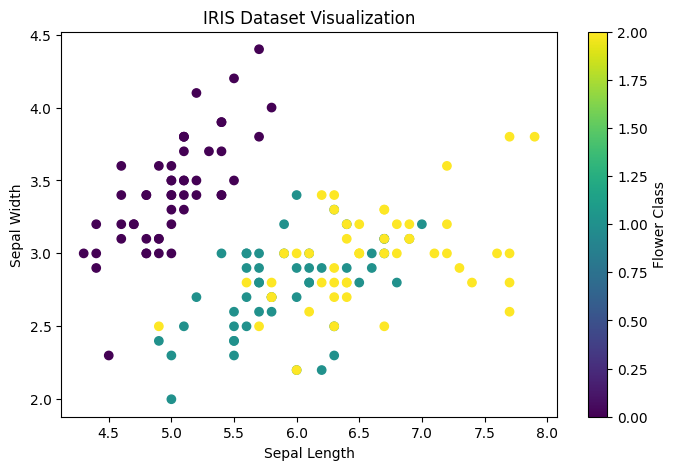

In [5]:
plt.figure(figsize=(8, 5))

plt.scatter(X[:, 0], X[:, 1], c=y, cmap='viridis')

plt.xlabel("Sepal Length")
plt.ylabel("Sepal Width")
plt.title("IRIS Dataset Visualization")

plt.colorbar(label="Flower Class")
plt.show()

In [6]:
def sigmoid(x):
    return 1 / (1 + np.exp(-x))

def tanh(x):
    return np.tanh(x)

def relu(x):
    return np.maximum(0, x)

def leaky_relu(x):
    return np.where(x > 0, x, 0.01 * x)

def elu(x):
    return np.where(x > 0, x, np.exp(x) - 1)

def softmax(x):
    exp_x = np.exp(x - np.max(x, axis=1, keepdims=True))
    return exp_x / np.sum(exp_x, axis=1, keepdims=True)


def manual_forward(X, activation="relu"):

    np.random.seed(42)

    W1 = np.random.randn(4, 16) * 0.1
    b1 = np.zeros((1, 16))

    W2 = np.random.randn(16, 3) * 0.1
    b2 = np.zeros((1, 3))

    Z1 = np.dot(X, W1) + b1

    if activation == "sigmoid":
        A1 = sigmoid(Z1)

    elif activation == "tanh":
        A1 = tanh(Z1)

    elif activation == "relu":
        A1 = relu(Z1)

    elif activation == "leaky_relu":
        A1 = leaky_relu(Z1)

    elif activation == "elu":
        A1 = elu(Z1)

    Z2 = np.dot(A1, W2) + b2

    output = softmax(Z2)

    return output


output = manual_forward(X_train[:5], "relu")

print("Manual Forward Propagation Output:")
print(output)

Manual Forward Propagation Output:
[[0.33677796 0.32674022 0.33648182]
 [0.33022211 0.33342518 0.33635271]
 [0.34460121 0.32735325 0.32804554]
 [0.34140842 0.3247428  0.33384878]
 [0.33373922 0.32912495 0.33713583]]


In [7]:
def build_model(activation):

    model = Sequential()

    model.add(Input(shape=(4,)))

    if activation == "leaky_relu":
        model.add(Dense(16))
        model.add(LeakyReLU(negative_slope=0.01))

    elif activation == "elu":
        model.add(Dense(16))
        model.add(ELU(alpha=1.0))

    else:
        model.add(Dense(16, activation=activation))

    model.add(Dense(3, activation='softmax'))

    model.compile(
        optimizer=Adam(learning_rate=0.001),
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )

    return model

In [8]:
activation_functions = [
    "sigmoid",
    "tanh",
    "relu",
    "leaky_relu",
    "elu"
]

models = {}
histories = {}
results = {}

class TrainingTimer(tf.keras.callbacks.Callback):

    def on_train_begin(self, logs=None):
        self.epoch_times = []
        self.start_time = time.time()

    def on_epoch_begin(self, epoch, logs=None):
        self.epoch_start = time.time()

    def on_epoch_end(self, epoch, logs=None):
        self.epoch_times.append(time.time() - self.epoch_start)


for activation in activation_functions:

    print("\nTraining with:", activation)

    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(42)

    model = build_model(activation)

    timer = TrainingTimer()

    start = time.time()

    history = model.fit(
        X_train,
        y_train,
        epochs=5,
        batch_size=16,
        validation_split=0.2,
        callbacks=[timer],
        verbose=1
    )

    total_time = time.time() - start

    test_loss, test_accuracy = model.evaluate(
        X_test,
        y_test,
        verbose=0
    )

    models[activation] = model
    histories[activation] = history

    results[activation] = {
        "Training Loss": history.history['loss'][-1],
        "Validation Accuracy": history.history['val_accuracy'][-1] * 100,
        "Test Accuracy": test_accuracy * 100,
        "Training Time": total_time,
        "Average Epoch Time": np.mean(timer.epoch_times)
    }

    print("Test Accuracy:", round(test_accuracy * 100, 2), "%")
    print("Training Time:", round(total_time, 4), "seconds")


Training with: sigmoid
Epoch 1/5
6/6 ━━━━━━━━━━━━━━━━━━━━ 7s 639ms/step - accuracy: 0.6146 - loss: 1.0775 - val_accuracy: 0.5833 - val_loss: 1.0913
Epoch 2/5
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - accuracy: 0.6771 - loss: 1.0566 - val_accuracy: 0.5833 - val_loss: 1.0700
Epoch 3/5
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step - accuracy: 0.6875 - loss: 1.0367 - val_accuracy: 0.5833 - val_loss: 1.0490
Epoch 4/5
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step - accuracy: 0.6875 - loss: 1.0174 - val_accuracy: 0.5833 - val_loss: 1.0288
Epoch 5/5
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step - accuracy: 0.6875 - loss: 0.9985 - val_accuracy: 0.5833 - val_loss: 1.0092
Test Accuracy: 66.67 %
Training Time: 8.4914 seconds

Training with: tanh
Epoch 1/5
6/6 ━━━━━━━━━━━━━━━━━━━━ 3s 313ms/step - accuracy: 0.5312 - loss: 1.0059 - val_accuracy: 0.6250 - val_loss: 0.9545
Epoch 2/5
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - accuracy: 0.6771 - loss: 0.9424 - val_accuracy: 0.6250 - val_loss: 0.8993
Epoch 3/5
6/6 ━━━━━━━━━━━━━━━━━━

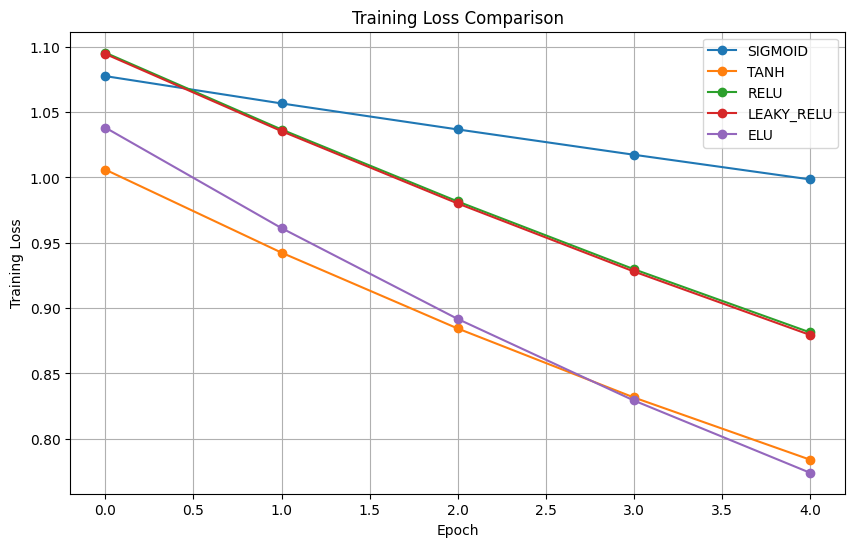

In [9]:
plt.figure(figsize=(10, 6))

for activation in activation_functions:

    plt.plot(
        histories[activation].history['loss'],
        marker='o',
        label=activation.upper()
    )

plt.title("Training Loss Comparison")
plt.xlabel("Epoch")
plt.ylabel("Training Loss")

plt.legend()
plt.grid(True)

plt.show()

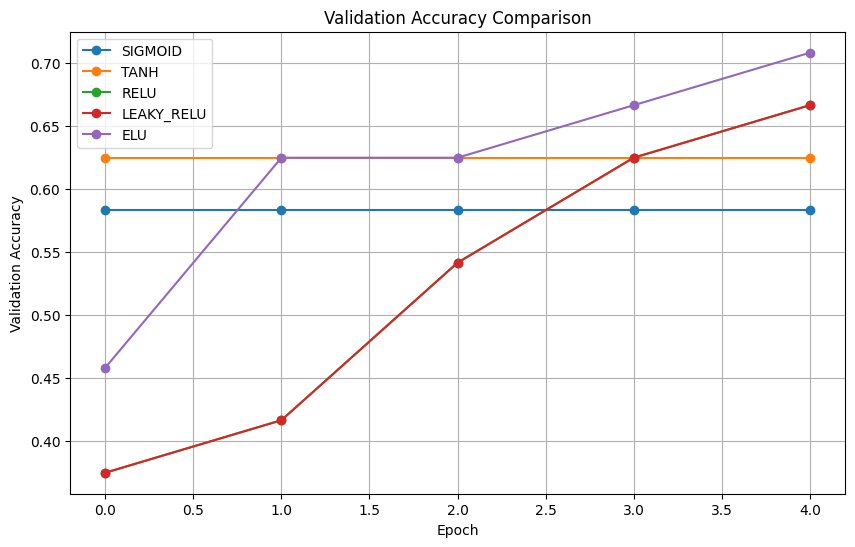

In [10]:
plt.figure(figsize=(10, 6))

for activation in activation_functions:

    plt.plot(
        histories[activation].history['val_accuracy'],
        marker='o',
        label=activation.upper()
    )

plt.title("Validation Accuracy Comparison")
plt.xlabel("Epoch")
plt.ylabel("Validation Accuracy")

plt.legend()
plt.grid(True)

plt.show()

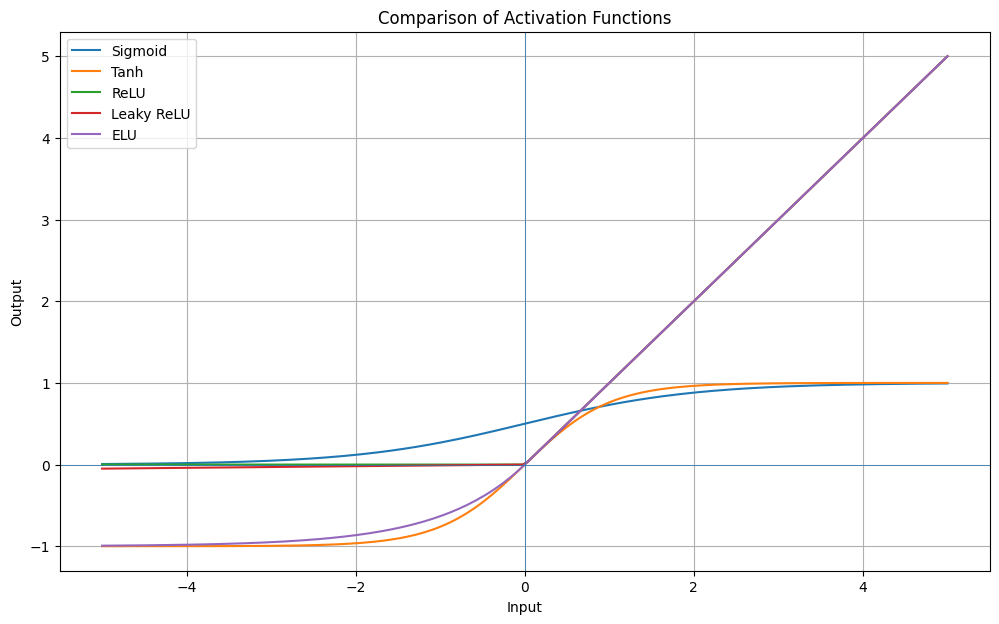

In [11]:
x = np.linspace(-5, 5, 200)

y_sigmoid = 1 / (1 + np.exp(-x))
y_tanh = np.tanh(x)
y_relu = np.maximum(0, x)
y_leaky_relu = np.where(x > 0, x, 0.01 * x)
y_elu = np.where(x > 0, x, np.exp(x) - 1)

plt.figure(figsize=(12, 7))

plt.plot(x, y_sigmoid, label='Sigmoid')
plt.plot(x, y_tanh, label='Tanh')
plt.plot(x, y_relu, label='ReLU')
plt.plot(x, y_leaky_relu, label='Leaky ReLU')
plt.plot(x, y_elu, label='ELU')

plt.title("Comparison of Activation Functions")
plt.xlabel("Input")
plt.ylabel("Output")

plt.axhline(0, linewidth=0.5)
plt.axvline(0, linewidth=0.5)

plt.legend()
plt.grid(True)

plt.show()

In [12]:
results_df = pd.DataFrame(results).T

print("\nACTIVATION FUNCTION COMPARISON")
print(results_df.round(4))


ACTIVATION FUNCTION COMPARISON
            Training Loss  Validation Accuracy  Test Accuracy  Training Time  \
sigmoid            0.9985              58.3333        66.6667         8.4914   
tanh               0.7841              62.5000        66.6667         3.6921   
relu               0.8814              66.6667        66.6667         2.2326   
leaky_relu         0.8795              66.6667        66.6667         2.4156   
elu                0.7740              70.8333        70.0000         2.1227   

            Average Epoch Time  
sigmoid                 1.6673  
tanh                    0.7244  
relu                    0.4357  
leaky_relu              0.4724  
elu                     0.4138  


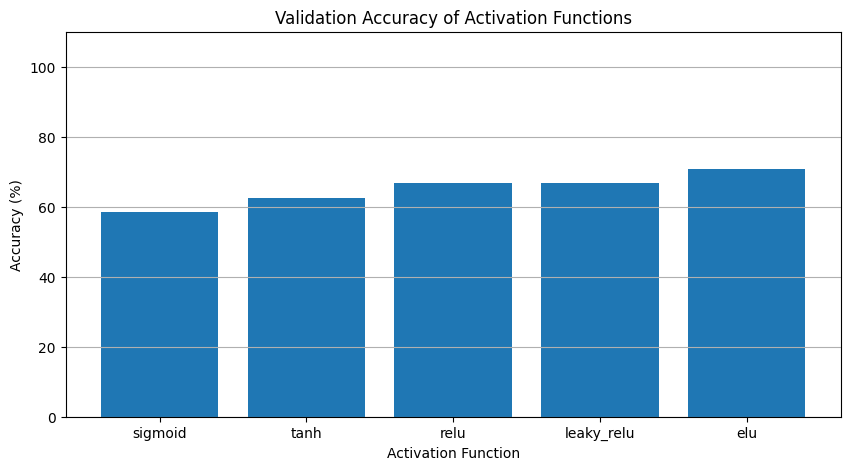

In [13]:
plt.figure(figsize=(10, 5))

plt.bar(
    results_df.index,
    results_df['Validation Accuracy']
)

plt.title("Validation Accuracy of Activation Functions")
plt.xlabel("Activation Function")
plt.ylabel("Accuracy (%)")

plt.ylim(0, 110)
plt.grid(axis='y')

plt.show()

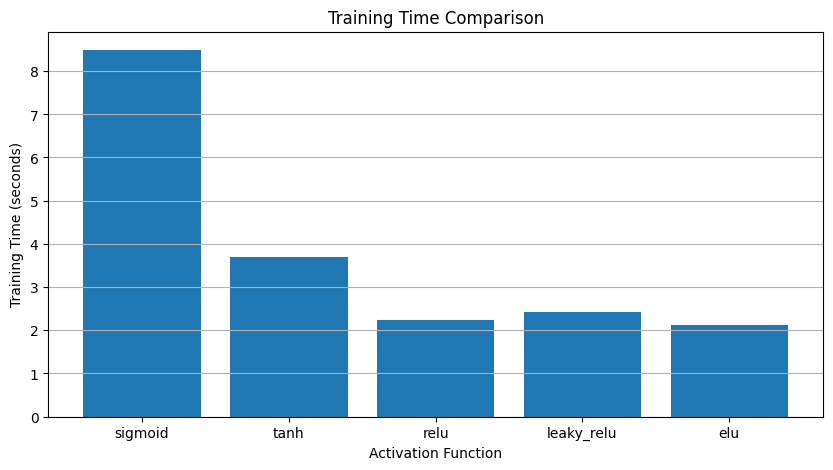

In [14]:
plt.figure(figsize=(10, 5))

plt.bar(
    results_df.index,
    results_df['Training Time']
)

plt.title("Training Time Comparison")
plt.xlabel("Activation Function")
plt.ylabel("Training Time (seconds)")

plt.grid(axis='y')

plt.show()

In [15]:
best_activation = results_df['Validation Accuracy'].idxmax()

print("Best Activation Function:", best_activation)

print(
    "Validation Accuracy:",
    round(results_df.loc[best_activation, 'Validation Accuracy'], 2),
    "%"
)

print(
    "Test Accuracy:",
    round(results_df.loc[best_activation, 'Test Accuracy'], 2),
    "%"
)

Best Activation Function: elu
Validation Accuracy: 70.83 %
Test Accuracy: 70.0 %
